# eda grafikleri

acn caltech saatlik doluluk ve oturum ozetleri
0 = kayit yok diye etiketliyorum hizmet disi ayrimi henuz maskelenmedi

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

project_dir = Path.cwd()
if project_dir.name == "notebooks":
    project_dir = project_dir.parent
if str(project_dir) not in sys.path:
    sys.path.insert(0, str(project_dir))

from src.load_data import build_occupancy_matrix, load_caltech_sessions, session_quality_report

sessions = load_caltech_sessions(project_dir / "data" / "raw" / "acn")
report = session_quality_report(sessions)
print(report)

occupancy = build_occupancy_matrix(sessions)
local_hours = occupancy.index.tz_convert("America/Los_Angeles")
mean_occ = occupancy.mean(axis=1)

print("matris", occupancy.shape)

Matplotlib is building the font cache; this may take a moment.


{'missing_times': 0, 'invalid_intervals': 0, 'duplicate_session_ids': 0, 'missing_sessionID': 0, 'missing_stationID': 0, 'missing_siteID': 0, 'n_sessions': 31424, 'n_stations': 55}


matris (29705, 55)


## saat ve haftanin gunune gore ortalama doluluk

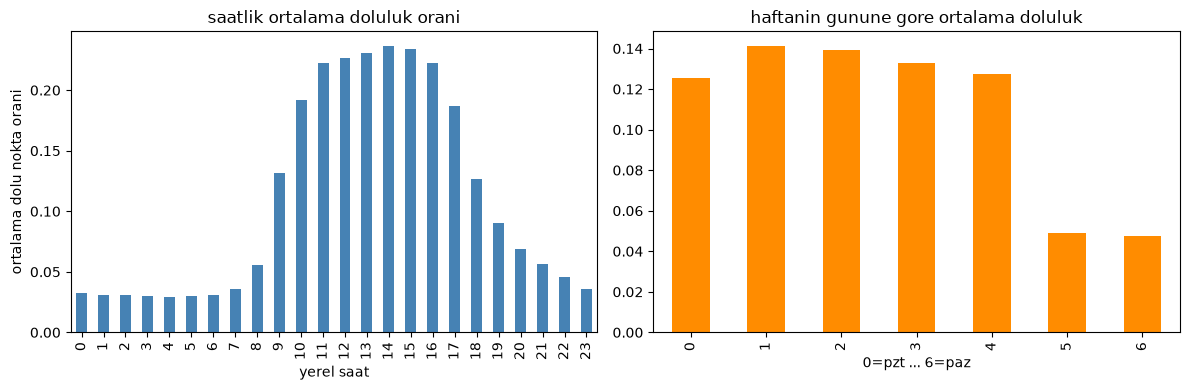

In [2]:
by_hour = mean_occ.groupby(local_hours.hour).mean()
by_dow = mean_occ.groupby(local_hours.dayofweek).mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
by_hour.plot(ax=axes[0], kind="bar", color="steelblue")
axes[0].set_title("saatlik ortalama doluluk orani")
axes[0].set_xlabel("yerel saat")
axes[0].set_ylabel("ortalama dolu nokta orani")

by_dow.plot(ax=axes[1], kind="bar", color="darkorange")
axes[1].set_title("haftanin gunune gore ortalama doluluk")
axes[1].set_xlabel("0=pzt ... 6=paz")
plt.tight_layout()
plt.show()

## aylik oturum sayisi

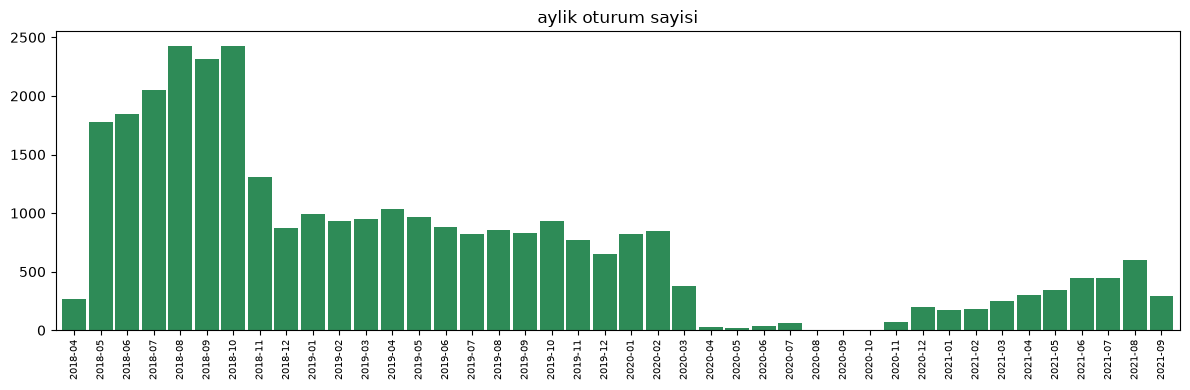

In [3]:
local_conn = sessions["connectionTime_utc"].dt.tz_convert("America/Los_Angeles")
monthly = sessions.groupby(local_conn.dt.strftime("%Y-%m")).size()
all_months = pd.period_range("2018-04", "2021-09", freq="M").astype(str)
monthly = monthly.reindex(all_months, fill_value=0)

fig, ax = plt.subplots(figsize=(12, 4))
monthly.plot(ax=ax, kind="bar", width=0.9, color="seagreen")
ax.set_title("aylik oturum sayisi")
ax.tick_params(axis="x", labelrotation=90, labelsize=7)
plt.tight_layout()
plt.show()

## noktalar arasi doluluk farki

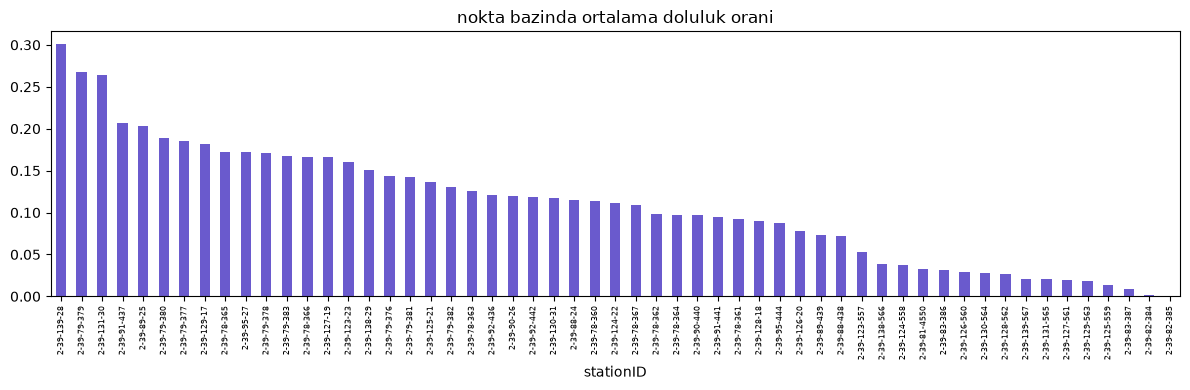

en yogun 5


stationID
2-39-139-28    0.301094
2-39-79-379    0.267194
2-39-131-30    0.263727
2-39-91-437    0.206733
2-39-89-25     0.202895
dtype: float64

en seyrek 5


stationID
2-39-129-563    0.018482
2-39-125-559    0.013533
2-39-83-387     0.008214
2-39-82-384     0.001818
2-39-82-385     0.000539
dtype: float64

In [4]:
station_rate = occupancy.mean().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(12, 4))
station_rate.plot(ax=ax, kind="bar", color="slateblue")
ax.set_title("nokta bazinda ortalama doluluk orani")
ax.set_xlabel("stationID")
ax.tick_params(axis="x", labelrotation=90, labelsize=6)
plt.tight_layout()
plt.show()

print("en yogun 5")
display(station_rate.head())
print("en seyrek 5")
display(station_rate.tail())

## oturum suresi dagilimi

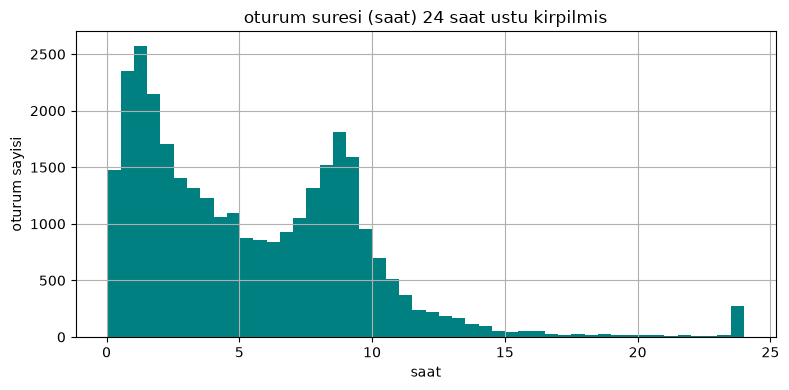

count    31424.000000
mean         5.652122
std          5.963686
min          0.034444
25%          1.866389
50%          4.730139
75%          8.467014
max        245.269167
dtype: float64


In [5]:
duration_hours = (
    sessions["disconnectTime_utc"] - sessions["connectionTime_utc"]
).dt.total_seconds() / 3600

fig, ax = plt.subplots(figsize=(8, 4))
duration_hours.clip(upper=24).hist(ax=ax, bins=48, color="teal")
ax.set_title("oturum suresi (saat) 24 saat ustu kirpilmis")
ax.set_xlabel("saat")
ax.set_ylabel("oturum sayisi")
plt.tight_layout()
plt.show()

print(duration_hours.describe())

## sonuc

grafikler acn caltech icin hazir
hava ile doluluk iliskisi open-meteo sonrasi eklenecek